In [2]:
%load_ext sql
%config SqlMagic.style = 'DEFAULT'


In [3]:
%sql postgresql+psycopg2://macbook@localhost:5432/goit_hw02


In [28]:
%pip install "prettytable==3.9.0"


  Attempting uninstall: prettytable
    Found existing installation: prettytable 3.18.0
    Uninstalling prettytable-3.18.0:
      Successfully uninstalled prettytable-3.18.0

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
%%sql

CREATE TABLE IF NOT EXISTS hw2_customers (
    customer_id BIGINT PRIMARY KEY,
    country VARCHAR(100) NOT NULL,
    registration_date DATE NOT NULL,
    acquisition_channel VARCHAR(100) NOT NULL
);

 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
Done.


[]

In [5]:
%%sql

SELECT *
FROM hw2_customers;

 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
0 rows affected.


customer_id,country,registration_date,acquisition_channel


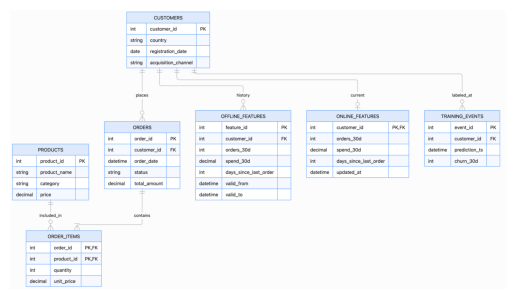

In [8]:
import matplotlib.pyplot as plt

image = plt.imread(
    "./diagram.png"
)

plt.imshow(image)
plt.axis("off")
plt.show()


In [6]:
%%sql

SET TIME ZONE 'UTC';

DROP TABLE IF EXISTS
    hw2_order_items,
    hw2_customer_features_online,
    hw2_training_events,
    hw2_customer_features_offline,
    hw2_orders,
    hw2_products,
    hw2_customers
CASCADE;

-- 1. CUSTOMERS
CREATE TABLE hw2_customers (
  customer_id BIGINT PRIMARY KEY,
  country VARCHAR(100) NOT NULL,
  registration_date DATE NOT NULL,
  acquisition_channel VARCHAR(100) NOT NULL
);

-- 2. PRODUCTS
CREATE TABLE hw2_products (
  product_id BIGINT PRIMARY KEY,
  product_name VARCHAR(255) NOT NULL,
  category VARCHAR(100) NOT NULL,
  price NUMERIC(12, 2) NOT NULL,

  CHECK (PRICE>=0)
);

-- 3. ORDERS
CREATE TABLE hw2_orders (
  order_id BIGINT PRIMARY KEY,
  customer_id BIGINT NOT NULL
      REFERENCES hw2_customers(customer_id),
  order_date TIMESTAMPTZ NOT NULL,
  status VARCHAR(50) NOT NULL,
  total_amount NUMERIC(12, 2) NOT NULL,

  CHECK(total_amount >= 0),

  CHECK (
    status IN (
      'pending',
      'completed',
      'cancelled',
      'refunded'
    )
  )
);

-- 4. ORDER_ITEMS (Bridge table)
CREATE TABLE hw2_order_items (
  order_id BIGINT NOT NULL
     REFERENCES hw2_orders(order_id),
  product_id BIGINT NOT NULL
     REFERENCES hw2_products(product_id),

  quantity INTEGER NOT NULL,
  unit_price NUMERIC(12, 2) NOT NULL,

  PRIMARY KEY (order_id, product_id),

  CHECK(quantity > 0),
  CHECK(unit_price >=0)
);

-- 5. OFFLINE FEATURE STORE
CREATE TABLE hw2_customer_features_offline (
    feature_id BIGINT
        GENERATED BY DEFAULT AS IDENTITY
        PRIMARY KEY,

    customer_id BIGINT NOT NULL
        REFERENCES hw2_customers(customer_id),

    orders_30d INTEGER NOT NULL,
    spend_30d NUMERIC(12, 2) NOT NULL,
    days_since_last_order INTEGER,

    valid_from TIMESTAMPTZ NOT NULL,
    valid_to TIMESTAMPTZ,

    CHECK (orders_30d >= 0),
    CHECK (spend_30d >= 0),

    CHECK (
        days_since_last_order IS NULL
        OR days_since_last_order >= 0
    ),

    CHECK (
        valid_to IS NULL
        OR valid_to > valid_from
    ),

    UNIQUE (customer_id, valid_from)
);

-- 6. ONLINE FEATURE STORE
CREATE TABLE hw2_customer_features_online (
    customer_id BIGINT PRIMARY KEY
        REFERENCES hw2_customers(customer_id),

    orders_30d INTEGER NOT NULL,
    spend_30d NUMERIC(12, 2) NOT NULL,
    days_since_last_order INTEGER,

    updated_at TIMESTAMPTZ NOT NULL
        DEFAULT CURRENT_TIMESTAMP,

    CHECK (orders_30d >= 0),
    CHECK (spend_30d >= 0),

    CHECK (
        days_since_last_order IS NULL
        OR days_since_last_order >= 0
    )
);


-- 7. TRAINING EVENTS
CREATE TABLE hw2_training_events (
    event_id BIGINT
        GENERATED BY DEFAULT AS IDENTITY
        PRIMARY KEY,

    customer_id BIGINT NOT NULL
        REFERENCES hw2_customers(customer_id),

    prediction_ts TIMESTAMPTZ NOT NULL,

    churn_30d INTEGER NOT NULL,

    CHECK (churn_30d IN (0, 1))
);


-- 8. INDEXES

-- Історичний пошук ознак на момент прогнозування
CREATE INDEX hw2_idx_customer_features_asof
ON hw2_customer_features_offline
    (customer_id, valid_from DESC);

-- Пошук замовлень клієнта за датою
CREATE INDEX hw2_idx_orders_customer_date
ON hw2_orders
    (customer_id, order_date DESC);

-- Пошук training events
CREATE INDEX hw2_idx_training_events_customer_ts
ON hw2_training_events
    (customer_id, prediction_ts);

-- Пошук товарів у замовленнях
CREATE INDEX hw2_idx_order_items_product
ON hw2_order_items
    (product_id);


 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
Done.
Done.
Done.
Done.
Done.
Done.
Done.
Done.
Done.
Done.
Done.
Done.
Done.


[]

**Завдання 3. Нормалізація**
### Нормалізація та денормалізація бази даних

**1. Нормалізація до третьої нормальної форми (3НФ)**

Таблиці `hw2_customers`, `hw2_products`, `hw2_orders`, `hw2_order_items` і `hw2_training_events` перебувають у 3НФ, оскільки їхні неключові атрибути залежать від первинного ключа, а транзитивні залежності між неключовими атрибутами відсутні.

**2. Функціональні залежності**

Під час декомпозиції враховано такі залежності:

- `customer_id → country, registration_date, acquisition_channel`
- `product_id → product_name, category, price`
- `order_id → customer_id, order_date, status, total_amount`
- `(order_id, product_id) → quantity, unit_price`
- `event_id → customer_id, prediction_ts, churn_30d`

Зв'язок Many-to-Many між замовленнями й товарами реалізовано через `hw2_order_items`, що усуває дублювання даних про товари в замовленнях.

**3. Денормалізація Feature Store**

Таблиця `hw2_customer_features_online` навмисно зберігає попередньо обчислені агреговані ознаки: `orders_30d`, `spend_30d` та `days_since_last_order`.

Це дозволяє отримувати всі ознаки одним lookup за `customer_id` (entity_id), забезпечувати низьку latency та уникати додаткових `JOIN` під час прогнозування.

**4. Ризики та синхронізація**

Дублювання ознак між offline- та online-рівнями створює ризик неузгодженості, якщо дані оновлюються в різний час.

Для синхронізації використовуватиметься регулярний ETL/ELT-процес: обчислення нових ознак на основі замовлень, збереження історичної версії в `hw2_customer_features_offline` та оновлення актуальних значень у `hw2_customer_features_online` через PostgreSQL `INSERT ... ON CONFLICT DO UPDATE` (UPSERT). Поле `updated_at` фіксуватиме час останнього оновлення.

**Завдання 4. Point-in-Time correctness**


Крок 1. Додаємо тестових клієнтів



In [9]:
%%sql
INSERT INTO hw2_customers
  (customer_id, country, registration_date, acquisition_channel)
  VALUES
    (1, 'UA', DATE '2024-01-10', 'Google Ads'),
    (2, 'PL', DATE '2024-02-20', 'Organic'),
    (42, 'UA', DATE '2024-03-15', 'Facebook Ads')
  ON CONFLICT (customer_id) DO NOTHING;

 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
1 rows affected.


[]

Крок 2. Створюємо історичні feature-дані

In [13]:

%%sql
DELETE FROM hw2_training_events
WHERE customer_id IN (1, 2, 42);

DELETE FROM hw2_customer_features_offline
WHERE customer_id IN (1, 2, 42);

INSERT INTO hw2_customer_features_offline
    (
        customer_id,
        orders_30d,
        spend_30d,
        days_since_last_order,
        valid_from,
        valid_to
    )
VALUES
    -- Customer 1: 4 versions
    (1, 8, 450.00, 2,
     TIMESTAMPTZ '2024-11-01 00:00:00+00',
     TIMESTAMPTZ '2024-12-01 00:00:00+00'),

    (1, 5, 300.00, 7,
     TIMESTAMPTZ '2024-12-01 00:00:00+00',
     TIMESTAMPTZ '2025-01-01 00:00:00+00'),

    (1, 2, 120.00, 15,
     TIMESTAMPTZ '2025-01-01 00:00:00+00',
     TIMESTAMPTZ '2025-02-01 00:00:00+00'),

    (1, 0, 0.00, 35,
     TIMESTAMPTZ '2025-02-01 00:00:00+00',
     NULL),

    -- Customer 2: 4 versions
    (2, 3, 150.00, 5,
     TIMESTAMPTZ '2024-11-01 00:00:00+00',
     TIMESTAMPTZ '2024-12-01 00:00:00+00'),

    (2, 6, 400.00, 3,
     TIMESTAMPTZ '2024-12-01 00:00:00+00',
     TIMESTAMPTZ '2025-01-01 00:00:00+00'),

    (2, 7, 500.00, 2,
     TIMESTAMPTZ '2025-01-01 00:00:00+00',
     TIMESTAMPTZ '2025-02-01 00:00:00+00'),

    (2, 9, 650.00, 1,
     TIMESTAMPTZ '2025-02-01 00:00:00+00',
     NULL),

    -- Customer 42: 4 versions
    (42, 2, 100.00, 10,
     TIMESTAMPTZ '2024-11-01 00:00:00+00',
     TIMESTAMPTZ '2024-12-15 00:00:00+00'),

    (42, 5, 200.00, 4,
     TIMESTAMPTZ '2024-12-15 00:00:00+00',
     TIMESTAMPTZ '2025-01-15 00:00:00+00'),

    (42, 3, 120.00, 12,
     TIMESTAMPTZ '2025-01-15 00:00:00+00',
     TIMESTAMPTZ '2025-02-15 00:00:00+00'),

    (42, 1, 35.00, 25,
     TIMESTAMPTZ '2025-02-15 00:00:00+00',
     NULL);


 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
0 rows affected.
0 rows affected.
12 rows affected.


[]

In [14]:

%%sql
SELECT
    customer_id,
    COUNT(*) AS versions_count
FROM hw2_customer_features_offline
GROUP BY customer_id
ORDER BY customer_id



 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
3 rows affected.


customer_id,versions_count
1,4
2,4
42,4


Крок 3. Додаємо Training Events

In [18]:
%%sql

INSERT INTO hw2_training_events 
(
  customer_id,
  prediction_ts,
  churn_30d
)

VALUES
    (1, TIMESTAMPTZ '2024-11-15 10:00:00+00', 0),
    (1, TIMESTAMPTZ '2024-12-15 10:00:00+00', 0),
    (1, TIMESTAMPTZ '2025-02-10 10:00:00+00', 1),

    (2, TIMESTAMPTZ '2024-11-20 10:00:00+00', 0),
    (2, TIMESTAMPTZ '2025-01-10 10:00:00+00', 0),
    (2, TIMESTAMPTZ '2025-02-20 10:00:00+00', 0),

    (42, TIMESTAMPTZ '2024-12-10 10:00:00+00', 0),
    (42, TIMESTAMPTZ '2024-12-20 10:00:00+00', 0),
    (42, TIMESTAMPTZ '2025-02-20 10:00:00+00', 1);

 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
9 rows affected.


[]

Крок 4. AS-OF SELECT — отримання історичних ознак
# Запит 1. Ознаки клієнта 42 на 10 грудня 2024 року


In [19]:

%%sql

SELECT
    customer_id,
    orders_30d,
    spend_30d,
    days_since_last_order,
    valid_from,
    valid_to
FROM hw2_customer_features_offline
WHERE customer_id = 42
  AND valid_from <=
      TIMESTAMPTZ '2024-12-10 10:00:00+00'
  AND (
      valid_to >
          TIMESTAMPTZ '2024-12-10 10:00:00+00'
      OR valid_to IS NULL
  );

 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
1 rows affected.


customer_id,orders_30d,spend_30d,days_since_last_order,valid_from,valid_to
42,2,100.00,10,2024-11-01 00:00:00+00:00,2024-12-15 00:00:00+00:00


In [20]:
%%sql

SELECT
    customer_id,
    orders_30d,
    spend_30d,
    days_since_last_order,
    valid_from,
    valid_to
FROM hw2_customer_features_offline
WHERE valid_from <=
      TIMESTAMPTZ '2025-01-10 10:00:00+00'
  AND (
      valid_to >
          TIMESTAMPTZ '2025-01-10 10:00:00+00'
      OR valid_to IS NULL
  )
ORDER BY customer_id;

 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
3 rows affected.


customer_id,orders_30d,spend_30d,days_since_last_order,valid_from,valid_to
1,2,120.00,15,2025-01-01 00:00:00+00:00,2025-02-01 00:00:00+00:00
2,7,500.00,2,2025-01-01 00:00:00+00:00,2025-02-01 00:00:00+00:00
42,5,200.00,4,2024-12-15 00:00:00+00:00,2025-01-15 00:00:00+00:00


# Крок 5. AS-OF JOIN для формування Training Dataset

In [21]:
%%sql

SELECT
    e.event_id,
    e.customer_id,
    e.prediction_ts,
    e.churn_30d,

    f.orders_30d,
    f.spend_30d,
    f.days_since_last_order,
    f.valid_from,
    f.valid_to

FROM hw2_training_events AS e

LEFT JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id

    AND f.valid_from <= e.prediction_ts

    AND (
        f.valid_to > e.prediction_ts
        OR f.valid_to IS NULL
    )

WHERE e.customer_id IN (1, 2, 42)

ORDER BY e.customer_id, e.prediction_ts;

 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
27 rows affected.


event_id,customer_id,prediction_ts,churn_30d,orders_30d,spend_30d,days_since_last_order,valid_from,valid_to
19,1,2024-11-15 10:00:00+00:00,0,8,450.00,2,2024-11-01 00:00:00+00:00,2024-12-01 00:00:00+00:00
10,1,2024-11-15 10:00:00+00:00,0,8,450.00,2,2024-11-01 00:00:00+00:00,2024-12-01 00:00:00+00:00
1,1,2024-11-15 10:00:00+00:00,0,8,450.00,2,2024-11-01 00:00:00+00:00,2024-12-01 00:00:00+00:00
20,1,2024-12-15 10:00:00+00:00,0,5,300.00,7,2024-12-01 00:00:00+00:00,2025-01-01 00:00:00+00:00
11,1,2024-12-15 10:00:00+00:00,0,5,300.00,7,2024-12-01 00:00:00+00:00,2025-01-01 00:00:00+00:00
2,1,2024-12-15 10:00:00+00:00,0,5,300.00,7,2024-12-01 00:00:00+00:00,2025-01-01 00:00:00+00:00
21,1,2025-02-10 10:00:00+00:00,1,0,0.00,35,2025-02-01 00:00:00+00:00,None
12,1,2025-02-10 10:00:00+00:00,1,0,0.00,35,2025-02-01 00:00:00+00:00,None
3,1,2025-02-10 10:00:00+00:00,1,0,0.00,35,2025-02-01 00:00:00+00:00,None
22,2,2024-11-20 10:00:00+00:00,0,3,150.00,5,2024-11-01 00:00:00+00:00,2024-12-01 00:00:00+00:00


Крок 6. Перевірка відсутності перекривання інтервалів

In [22]:
%%sql

SELECT
    a.customer_id,
    a.valid_from AS a_from,
    a.valid_to AS a_to,
    b.valid_from AS b_from,
    b.valid_to AS b_to

FROM hw2_customer_features_offline AS a

JOIN hw2_customer_features_offline AS b
    ON a.customer_id = b.customer_id

    AND a.feature_id < b.feature_id

    AND a.valid_from <
        COALESCE(
            b.valid_to,
            'infinity'::timestamptz
        )

    AND b.valid_from <
        COALESCE(
            a.valid_to,
            'infinity'::timestamptz
        );

 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
0 rows affected.


customer_id,a_from,a_to,b_from,b_to


Крок 7. Демонстрація неправильного JOIN

In [23]:
%%sql

SELECT
    e.event_id,
    e.customer_id,
    e.prediction_ts,
    f.orders_30d,
    f.spend_30d,
    f.valid_from

FROM hw2_training_events AS e

JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id

WHERE e.customer_id = 42

ORDER BY e.prediction_ts, f.valid_from;

 * postgresql+psycopg2://macbook@localhost:5432/goit_hw02
36 rows affected.


event_id,customer_id,prediction_ts,orders_30d,spend_30d,valid_from
25,42,2024-12-10 10:00:00+00:00,2,100.00,2024-11-01 00:00:00+00:00
7,42,2024-12-10 10:00:00+00:00,2,100.00,2024-11-01 00:00:00+00:00
16,42,2024-12-10 10:00:00+00:00,2,100.00,2024-11-01 00:00:00+00:00
25,42,2024-12-10 10:00:00+00:00,5,200.00,2024-12-15 00:00:00+00:00
16,42,2024-12-10 10:00:00+00:00,5,200.00,2024-12-15 00:00:00+00:00
7,42,2024-12-10 10:00:00+00:00,5,200.00,2024-12-15 00:00:00+00:00
25,42,2024-12-10 10:00:00+00:00,3,120.00,2025-01-15 00:00:00+00:00
16,42,2024-12-10 10:00:00+00:00,3,120.00,2025-01-15 00:00:00+00:00
7,42,2024-12-10 10:00:00+00:00,3,120.00,2025-01-15 00:00:00+00:00
25,42,2024-12-10 10:00:00+00:00,1,35.00,2025-02-15 00:00:00+00:00


### Point-in-Time Correctness та AS-OF JOIN

Для формування часово коректних навчальних даних використовується AS-OF JOIN між `hw2_training_events` та `hw2_customer_features_offline`.

**1. Чому використовується `valid_from <= prediction_ts`?**

Ця умова гарантує, що на момент прогнозування відповідна версія ознак уже існувала. Версії, створені після `prediction_ts`, не потрапляють до навчальної вибірки.

**2. Чому використовується `valid_to > prediction_ts OR valid_to IS NULL`?**

Умова перевіряє, що версія ознак ще була чинною на момент прогнозування. Значення `NULL` у `valid_to` означає, що версія є поточною та не має визначеної дати завершення.

**3. Чому використовуються напіввідкриті інтервали `[valid_from, valid_to)`?**

Початок інтервалу включається, а кінець — ні. Це дозволяє створювати послідовні версії без перекривання. Наприклад, версія, яка закінчується 15 грудня, не буде чинною одночасно з новою версією, яка починається цього дня.

**4. Що станеться без часового фільтра?**

Звичайний `JOIN` лише за `customer_id` приєднає всі історичні версії ознак до кожної навчальної події. Це створить дублікати та дозволить моделі використовувати майбутні значення `orders_30d`, `spend_30d` і `days_since_last_order`.

Такий витік інформації (*data leakage*) може призвести до завищеної оцінки якості ML-моделі.

Отже, AS-OF JOIN забезпечує використання лише тих ознак, які були доступні на момент прогнозування, що є необхідною умовою коректного навчання моделі Customer Churn Prediction.

## Завдання 5. Reflection

### 1. Найскладніший етап проєктування

Найскладнішим для мене було забезпечення **point-in-time correctness**, оскільки потрібно було не просто зберігати історичні дані, а правильно визначати, які ознаки були доступні на конкретний момент прогнозування. Особливу увагу я приділила умовам `valid_from <= prediction_ts` та `valid_to > prediction_ts OR valid_to IS NULL`. Використання AS-OF JOIN дозволило уникнути дублювання навчальних записів і витоку майбутніх даних (*data leakage*).

### 2. Проєктні компроміси

Для сценарію **Customer Churn Prediction** я нормалізувала бізнесові сутності `customers`, `products`, `orders` та `order_items` до третьої нормальної форми (3НФ). Зв'язок Many-to-Many між замовленнями й товарами реалізувала через bridge-таблицю `order_items`.

Водночас для `online feature store` використала денормалізацію: ознаки `orders_30d`, `spend_30d` та `days_since_last_order` зберігаються в одному рядку для кожного клієнта. Це дозволяє швидко отримувати дані без додаткових JOIN. Історичні версії зберігаються окремо в `offline feature store`, що спрощує навчання моделі.

### 3. Оптимізація Online Feature Store

Якби система обслуговувала мільйони користувачів, я б залишила денормалізовану структуру з `customer_id` як PRIMARY KEY. Для зменшення latency використала б попередню матеріалізацію ознак, кешування часто запитуваних даних і горизонтальне масштабування. Також важливо контролювати свіжість ознак через `updated_at`, щоб модель не використовувала застарілу інформацію.

### 4. Ризики еволюції схеми

Протягом шести місяців можуть змінитися назви, типи або логіка обчислення ознак. Наприклад, `spend_30d` може почати враховувати повернення коштів, що змінить його семантику.

Для зменшення ризиків я б використовувала версіонування feature-схем, документування змін і SQL-міграції. Старі версії ознак варто зберігати, доки їх використовують попередні версії ML-моделей. Це забезпечить сумісність і стабільність прогнозування.